In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
np.random.seed(42)
CREATE_DATA = False

In [12]:
def create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"]):

    # Generate client-level data
    client_ids = np.arange(1, num_clients + 1)

    # Income: Should follow a right skewed distribution (log-normal)
    # Adjusting the income distribution to follow a log-normal distribution (right-skewed, long tail)
    mean_income = 10  # Log-normal mean
    sigma_income = 0.6  # Log-normal standard deviation

    # Generate income values (skewed distribution)
    client_incomes = np.random.lognormal(mean=mean_income, sigma=sigma_income, size=num_clients)
    client_incomes = np.interp(client_incomes, (client_incomes.min(), client_incomes.max()), (20000, 200000))

    #client_incomes = np.random.uniform(20000, 100000, size=num_clients)  # Continuous feature: income
    client_spending_categories = np.random.choice(client_categories, size=num_clients)  # Categorical feature

    # Map spending categories to a numerical effect (low = 0.8, mid = 1, high = 1.2)
    category_effects = {"low_spender": 0.8, "mid_spender": 1, "high_spender": 1.2}
    product_base_prices = {1: (10, 30), 2: (15, 50), 3: (5, 25)}

    data = []
    for _ in range(num_transactions):
        client = np.random.choice(client_ids)
        product = np.random.randint(1, num_products + 1)

        # Determine product base price range
        base_price_min, base_price_max = product_base_prices[product]
        mean_price = (base_price_min + base_price_max) / 2

        # Client attributes
        income = client_incomes[client - 1]
        category = client_spending_categories[client - 1]
        category_multiplier = category_effects[category]

        # Price is sampled randomly within the product's base range
        price = np.random.uniform(base_price_min, base_price_max)

        # Amount bought depends on price (inverse relation) and income (higher income buys more)
        base_demand = np.random.uniform(5, 20)  # Base demand per product
        income_factor = (income / 200000)  # Scaled income effect (higher income = more purchases)
        
        print("&"*50)
        print("price: ", price)
        print("mean_price: ", mean_price)
        print("price / mean_price: ", price / mean_price)
        print("(price / mean_price)**2: ", (price / mean_price)**2)
        print("(1 / (1 + (price / mean_price)**2)): ", (1 / (1 + (price / mean_price)**2)))
        print("&"*50)
        #amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (1 + (price / mean_price)**2))) + np.random.normal(0, 1))
        amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (price / mean_price)**2)) + np.random.normal(0, 1))

        data.append([client, product, price, amount_bought, income, category])

    # Create DataFrame
    df = pd.DataFrame(data, columns=["client_id", "product_id", "offered_price", "amount_bought", "income", "client_category"])
    df["amount_bought"] = df["amount_bought"].round().astype(int)
    df["amount_bought"] = df["amount_bought"].clip(lower=0)  # Ensure no negative values

    df_name_to_save = f"synthetic_dataset_{num_clients}clients_{num_transactions}trans.csv"
    df.to_csv("data/" + df_name_to_save, index=False)
    return df, df_name_to_save




In [13]:
if CREATE_DATA:
    print("Creating synthetic data...")
    df, df_name = create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"])

In [14]:
df = pd.read_csv("data/synthetic_dataset_100clients_1000trans.csv")
df.head()

,client_id,product_id,offered_price,amount_bought,income,client_category
0,86,1,16.837593,2,65711.596821,low_spender
1,62,1,19.483477,2,68292.437850,mid_spender
2,48,1,19.469435,0,25123.362809,low_spender
3,10,2,37.228278,0,44011.061826,mid_spender
4,95,2,36.905097,2,49757.394042,low_spender


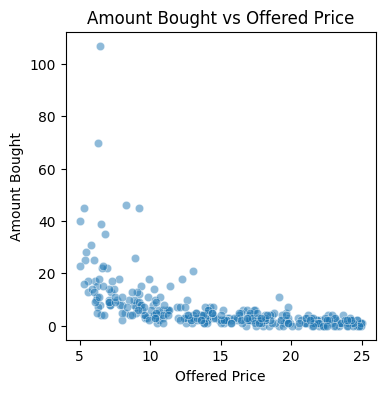

In [15]:
df_filtered = df[df['product_id'] == 3]

plt.figure(figsize=(4, 4))
sns.scatterplot(x=df_filtered["offered_price"], y=df_filtered["amount_bought"], alpha=0.5)
plt.xlabel("Offered Price")
plt.ylabel("Amount Bought")
plt.title("Amount Bought vs Offered Price")
plt.show()


In [26]:
target = 'amount_bought'
numerical_features = ['offered_price', 'income']
categorical_features = ['client_category']

In [28]:
correlation_matrix = df[numerical_features + [target]].corr()
print(correlation_matrix)


               offered_price    income  amount_bought
offered_price       1.000000 -0.020052      -0.406247
income             -0.020052  1.000000       0.461588
amount_bought      -0.406247  0.461588       1.000000


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(1)

In [29]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [30]:
# Model definition
class distModel(nn.Module):
    def __init__(self, input_size, hidden_layers, hidden_size, drop):
        super().__init__() # Call the parent class (nn.Module) constructor.
        self.input_size = input_size
        self.hidden_layers = hidden_layers
        self.hidden_size = hidden_size
        self.drop = drop

        # Define the input layer
        self.input_layer = nn.Linear(self.input_size, self.hidden_size)

        # Define the hidden layers
        self.hidden_layers = nn.ModuleList([nn.Linear(self.hidden_size, self.hidden_size) for _ in range(self.hidden_layers)])

        # Output mean Layer
        self.output_mean_layer = nn.Linear(self.hidden_size, 1)
        
        # Output var Layer
        self.output_sd_layer = nn.Linear(self.hidden_size, 1)

        # Define the activation function
        self.relu = nn.ReLU()

        # Define the dropout layer
        self.dropout = nn.Dropout(self.drop)

    def forward(self, x):
        # Define the forward pass
        x = self.relu(self.input_layer(x))
        for hidden_layer in self.hidden_layers:
            x = self.relu(hidden_layer(x))
            x = self.dropout(x)
        mean = self.output_mean_layer(x)# TODO: relu?
        sd = self.output_sd_layer(x) # TODO: relu?
        return mean, sd


In [31]:
class PandasDataset(Dataset):
    def __init__(self, X, y=None, transform=None):
        self.X = X.values if isinstance(X, pd.DataFrame) else X
        self.y = y.values if isinstance(y, pd.Series) else y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32)
        if self.transform:
            x = self.transform(x)
        if self.y is not None:
            y = torch.tensor(self.y[idx], dtype=torch.float32)
            return x, y
        return x

In [72]:

# Define trainer class
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

class Trainer():
    def __init__(self, X, y, model_config, training_config):
        self.X = X
        self.y = y

        self.model_config = model_config
        self.training_config = training_config

        # Definde the model
        self.model = distModel(input_size=self.X.shape[1], hidden_layers=self.model_config['hidden_layers'], hidden_size=self.model_config['hidden_size'], drop=self.model_config['drop']).to(device)

        # Define criterion: https://pytorch.org/docs/stable/generated/torch.nn.GaussianNLLLoss.html
        self.criterion = nn.GaussianNLLLoss()

    def create_data_partitions(self, create_test=True, test_size=0.2, val_size=0.1, random_state=42):
        '''
        Splits self.X and self.y into train, validation, and optionally test sets.

        Parameters:
        - create_test (bool): Whether to create a test set.
        - test_size (float): Proportion of data for the test set (if created).
        - val_size (float): Proportion of the training data for validation.
        - random_state (int): Random seed for reproducibility.

        Returns:
        - Dictionaries containing the partitions.
        '''
        X_train, X_temp, y_train, y_temp = train_test_split(self.X, self.y, 
                                                            test_size=(test_size + val_size) if create_test else val_size, 
                                                            random_state=random_state)
        
        self.X_train = X_train
        self.X_val = X_temp
        self.y_train = y_train
        self.y_temp = y_temp
        
        if create_test:
            X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, 
                                                            test_size=test_size / (test_size + val_size), 
                                                            random_state=random_state)
            self.X_val = X_val
            self.X_test = X_test
            self.y_val = y_val
            self.y_test = y_test
            
    def train(self):
        torch.cuda.empty_cache()

        train_ds = PandasDataset(self.X_train, self.y_train)
        val_ds = PandasDataset(self.X_val, self.y_val)
        
        train_dl = DataLoader(train_ds, batch_size = self.training_config['batchsize'], shuffle=True)
        val_dl = DataLoader(val_ds, batch_size=len(val_ds)) # self.training_config['batchsize']?

        iters = self.training_config['iters']
        # Define optimizer: https://pytorch.org/docs/stable/generated/torch.optim.Adam.html
        optimizer = optim.Adam(self.model.parameters(), lr = self.training_config['lr'], weight_decay=self.training_config['wd'])

        best_loss = float('inf')
        for epoch in range(iters):
            ## Training
            self.model.train()
            self.train_loss = AverageMeter()
            for i, (x, y) in enumerate(train_dl):
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                mean, sd = self.model(x)
                loss = self.criterion(mean, y, sd**2)
                loss.backward()
                optimizer.step()
                self.train_loss.update(loss.item(), x.size(0))

            ## Validation
            self.model.eval()
            self.val_loss = AverageMeter()
            with torch.no_grad():
                for i, (x, y) in enumerate(val_dl):
                    x, y = x.to(device), y.to(device)
                    mean, sd = self.model(x)
                    loss = self.criterion(mean, y, sd**2)
                    self.val_loss.update(loss.item(), x.size(0))

            if self.val_loss.avg < best_loss:
                best_loss = self.val_loss.avg
                torch.save(self.model.state_dict(), 'best_model.pth')

            print(f'Epoch {epoch+1}/{iters} - Train Loss: {self.train_loss.avg:.4f}, Val Loss: {self.val_loss.avg:.4f}')

    def test(self):
        test_ds = PandasDataset(self.X_test, self.y_test)
        test_dl = DataLoader(test_ds, batch_size=len(test_ds)) # self.training_config['batchsize']?

        self.model.load_state_dict(torch.load('best_model.pth'))
        self.model.eval()

        ## Testing
        test_loss = AverageMeter()
        with torch.no_grad():
            for i, (x, y) in enumerate(test_dl):
                x, y = x.to(device), y.to(device)
                mean, sd = self.model(x)
                loss = self.criterion(mean, y, sd**2)
                test_loss.update(loss.item(), x.size(0))
        
        print(f'Test Loss: {test_loss.avg:.4f}')
    
    def predict(self, X):
        self.model.load_state_dict(torch.load('best_model.pth'))
        self.model.eval()

        pred_ds = PandasDataset(X)
        pred_dl = DataLoader(pred_ds, batch_size=len(pred_ds)) # self.training_config['batchsize']?

        with torch.no_grad():
            for i, x in enumerate(pred_dl):
                x = x.to(device)
                mean, sd = self.model(x)
            
            mean_pred = mean.detach().cpu().numpy()
            sd_pred = sd.detach().cpu().numpy()
        
        return mean_pred, sd_pred

In [73]:
model_config = {
    'hidden_layers': 2,
    'hidden_size': 64,
    'drop': 0.2
    }

training_config = {
    'lr': 0.0001,
    'wd': 0.0001,
    'batchsize': 64,
    'iters': 500
    }

trainer = Trainer(df[['offered_price', 'income']], df['amount_bought'], model_config=model_config, training_config=training_config)

trainer.create_data_partitions()

print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)

trainer.train()

trainer.test()

X_train shape:  (699, 2)
X_val shape:  (100, 2)
X_test shape:  (201, 2)
Epoch 1/500 - Train Loss: 194.6093, Val Loss: 7.5807
Epoch 2/500 - Train Loss: 62.8634, Val Loss: 7.5524
Epoch 3/500 - Train Loss: 282.0924, Val Loss: 7.5230
Epoch 4/500 - Train Loss: 42.2429, Val Loss: 7.5308
Epoch 5/500 - Train Loss: 153.0726, Val Loss: 7.4962
Epoch 6/500 - Train Loss: 345.2811, Val Loss: 7.5698
Epoch 7/500 - Train Loss: 74.1026, Val Loss: 7.6907
Epoch 8/500 - Train Loss: 89.8946, Val Loss: 7.7471
Epoch 9/500 - Train Loss: 438.7742, Val Loss: 7.8264
Epoch 10/500 - Train Loss: 49.7460, Val Loss: 7.9282
Epoch 11/500 - Train Loss: 118.4582, Val Loss: 7.9705
Epoch 12/500 - Train Loss: 8.7609, Val Loss: 7.9954
Epoch 13/500 - Train Loss: 10.8943, Val Loss: 8.0035
Epoch 14/500 - Train Loss: 11.4042, Val Loss: 8.0062
Epoch 15/500 - Train Loss: 10.7695, Val Loss: 8.0076
Epoch 16/500 - Train Loss: 29.1124, Val Loss: 8.0082
Epoch 17/500 - Train Loss: 8.8384, Val Loss: 8.0081
Epoch 18/500 - Train Loss: 8.418